# Excercise resampling method
# Author:Haoyang Qian
# Date:2026/10/13 


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold

In [2]:
df_pollution=pd.read_csv('pollution_cleaneddata.csv')

In [3]:
df_pollution.head()

,PREC,JANT,JULT,OVR65,POPN,EDUC,HOUS,DENS,NONW,WWDRK,POOR,HC,NOX,SO@,HUMID,MORT
0,36.0,27.0,71.0,8.1,3.34,11.4,81.5,3243.0,8.8,42.6,11.7,21.0,15.0,59.0,59.0,921.870
1,35.0,23.0,72.0,11.1,3.14,11.0,78.8,4281.0,3.5,50.7,14.4,8.0,10.0,39.0,57.0,997.875
2,44.0,29.0,74.0,10.4,3.21,9.8,81.6,4260.0,0.8,39.4,12.4,6.0,6.0,33.0,54.0,962.354
3,47.0,45.0,79.0,6.5,3.41,11.1,77.5,3125.0,27.1,50.2,20.6,18.0,8.0,24.0,56.0,982.291
4,43.0,35.0,77.0,7.6,3.44,9.6,84.6,6441.0,24.4,43.7,14.3,43.0,38.0,206.0,55.0,1071.289


In [4]:
X = df_pollution[['JULT']].values
y = df_pollution['MORT'].values
np.random.seed(42)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=42)

In [8]:
n = 4
degree_p = np.arange(1,n+1,1)
train_mses = []
test_mses = []
for degree in degree_p:
    poly = PolynomialFeatures(degree=degree)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)
    
    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    
    train_pred = model.predict(X_train_poly)
    test_pred = model.predict(X_test_poly)
    
    train_mses.append(mean_squared_error(y_train, train_pred))
    test_mses.append(mean_squared_error(y_test, test_pred))

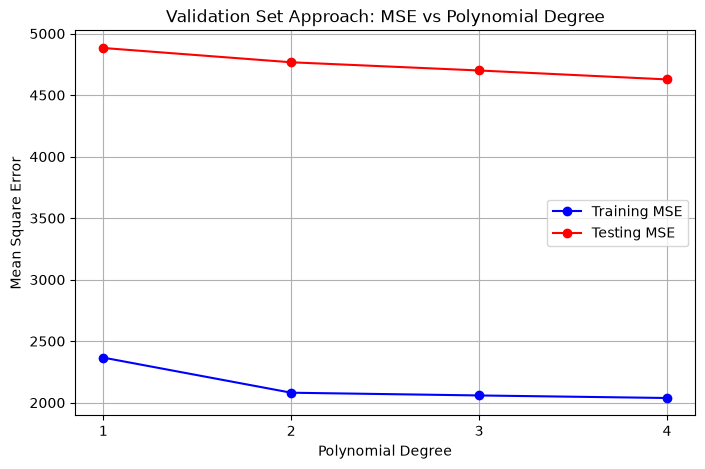

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(degree_p, train_mses, marker='o', label='Training MSE', color='blue')
plt.plot(degree_p, test_mses, marker='o', label='Testing MSE', color='red')
plt.xticks(degree_p)
plt.xlabel('Polynomial Degree')
plt.ylabel('Mean Square Error')
plt.title('Validation Set Approach: MSE vs Polynomial Degree')
plt.legend()
plt.grid(True)
plt.show()

### I recommend the degree of the polynomial to be 2 to meet a lower MSE without a too complex model which may leading to overfitting.

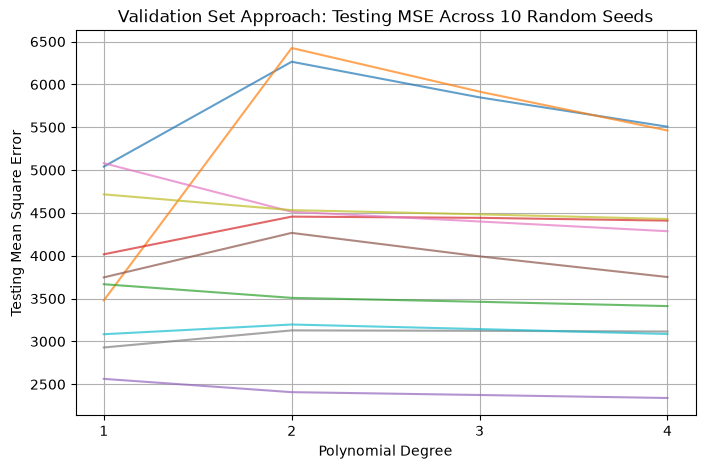

In [24]:
plt.figure(figsize=(8, 5))
seeds = np.arange(1,11,1)

for seed in seeds:
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.5, random_state=seed)
    test_mses_seed = []
    
    for degree in degree_p:
        poly = PolynomialFeatures(degree=degree)
        X_tr_poly = poly.fit_transform(X_tr)
        X_te_poly = poly.transform(X_te)
        
        model = LinearRegression()
        model.fit(X_tr_poly, y_tr)
        
        test_pred = model.predict(X_te_poly)
        test_mses_seed.append(mean_squared_error(y_te, test_pred))
        
    plt.plot(degree_p, test_mses_seed, alpha=0.7, label=f'Seed {seed}')

plt.xticks(degree_p)
plt.xlabel('Polynomial Degree')
plt.ylabel('Testing Mean Square Error')
plt.title('Validation Set Approach: Testing MSE Across 10 Random Seeds')
plt.grid(True)
plt.show()

### Result from different random seeds are not quite similar, we need to conduct cross-validation.

In [20]:
p = 2
kf = KFold(n_splits=3, shuffle=True, random_state=42)

fold_mses = []
for train_idx, val_idx in kf.split(X):
    X_train, X_val = X[train_idx], X[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]
    
    poly = PolynomialFeatures(degree=p)
    X_train_poly = poly.fit_transform(X_train)
    X_val_poly = poly.transform(X_val)
    
    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    
    y_pred = model.predict(X_val_poly)
    fold_mses.append(mean_squared_error(y_val, y_pred))

cv_mse_k3 = np.mean(fold_mses)
print(f"MSE for each of the 3 folds: {fold_mses}")
print(f"Overall 3-Fold CV MSE (degree={p}): {cv_mse_k3:.2f}")

MSE for each of the 3 folds: [5427.166141038, 3542.749041753519, 3799.611760931524]
Overall 3-Fold CV MSE (degree=2): 4256.51


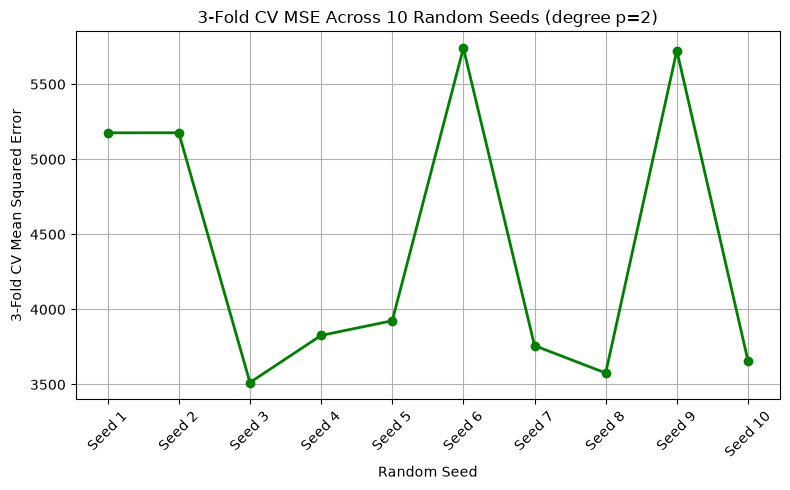

In [25]:
seeds = np.arange(1,11,1)
cv_mses_seeds = []

for seed in seeds:
    kf = KFold(n_splits=3, shuffle=True, random_state=seed)
    mses = []
    
    for train_idx, val_idx in kf.split(X):
        X_tr, X_va = X[train_idx], X[val_idx]
        y_tr, y_va = y[train_idx], y[val_idx]
        
        poly = PolynomialFeatures(degree=p)
        X_tr_poly = poly.fit_transform(X_tr)
        X_va_poly = poly.transform(X_va)
        
        model = LinearRegression()
        model.fit(X_tr_poly, y_tr)
        
        y_pred = model.predict(X_va_poly)
        mses.append(mean_squared_error(y_va, y_pred))
        
    cv_mses_seeds.append(np.mean(mses))

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), cv_mses_seeds, marker='o', color='green', linewidth=2)
plt.xticks(range(1, 11), labels=[f'Seed {s}' for s in seeds], rotation=45)
plt.xlabel('Random Seed')
plt.ylabel('3-Fold CV Mean Squared Error')
plt.title('3-Fold CV MSE Across 10 Random Seeds (degree p=2)')
plt.grid(True)
plt.tight_layout()
plt.show()

### The MSE based on different random seeds seem not similar but show a more stable result.

## The Bootstrap

In [30]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

df_bird = pd.read_csv('bird_count.csv')

model_orig = smf.poisson('count ~ yr', data=df_bird).fit(disp=0)
beta1_hat = model_orig.params['yr']
print(f"Original estimated slope (beta1_hat): {beta1_hat:.4f}")

B = 1000
bootstrap_slopes = []

np.random.seed(42) 

for _ in range(B):
    boot_df = df_bird.sample(frac=1.0, replace=True)
    boot_model = smf.poisson('count ~ yr', data=boot_df).fit(disp=0)
    bootstrap_slopes.append(boot_model.params['yr'])

se_beta1 = np.std(bootstrap_slopes, ddof=1)

print(f"Bootstrap Standard Error of slope: {se_beta1:.4f}")

Original estimated slope (beta1_hat): -0.0324
Bootstrap Standard Error of slope: 0.0345


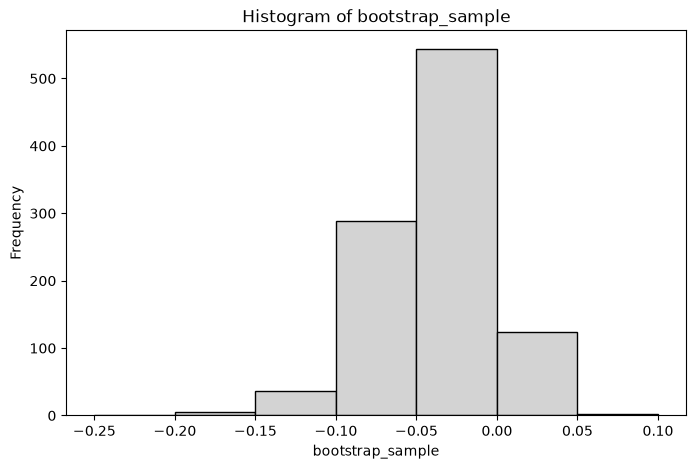

Calculated Bootstrap Standard Error: 0.034452


In [31]:
plt.figure(figsize=(8, 5))
plt.hist(bootstrap_slopes, bins=[-0.25, -0.20, -0.15, -0.10, -0.05, 0.00, 0.05, 0.10], 
         color='lightgray', edgecolor='black')
plt.xlabel('bootstrap_sample')
plt.ylabel('Frequency')
plt.title('Histogram of bootstrap_sample')
plt.show()

boot_se = np.std(bootstrap_slopes, ddof=1)
print(f"Calculated Bootstrap Standard Deviation: {boot_se:.6f}")